<a href="https://colab.research.google.com/github/dilarabcde/acrima-glaucoma-detection/blob/main/03_ACRIMA_Transfer_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
from pathlib import Path
import pandas as pd
import torch

# Google Drive bağlantısı
drive.mount("/content/drive")

# Proje klasörü
ROOT = Path(
    "/content/drive/MyDrive/ACRIMA_Glaucoma_Project"
)

# Daha önce kaydettiğimiz veri bölmeleri
train_df = pd.read_csv(
    ROOT / "data/splits/train.csv"
)

val_df = pd.read_csv(
    ROOT / "data/splits/val.csv"
)

# GPU kontrolü
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Kullanılan cihaz:", device)

# Veri kümelerinin örtüşmediğini kontrol et
assert set(train_df["dosya_adi"]).isdisjoint(
    set(val_df["dosya_adi"])
)

print("Train/Validation ayrımı kontrol edildi.")


Mounted at /content/drive
Training: 493
Validation: 106
Kullanılan cihaz: cuda
Train/Validation ayrımı kontrol edildi.


In [ ]:

import zipfile
from pathlib import Path

# Veri setinin bulunduğu ZIP dosyası
zip_path = ROOT / "Database.zip"

# Colab geçici diskindeki klasör
extract_path = Path("/content/acrima_data")
extract_path.mkdir(parents=True, exist_ok=True)

# ZIP dosyasını aç
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

# Görüntü klasörü
image_dir = extract_path / "Database" / "Images"

# JPG görüntülerini listele
image_files = [
    p for p in image_dir.iterdir()
    if p.is_file() and p.suffix.lower() == ".jpg"
]

print("Görüntü klasörü:", image_dir.exists())
print("Toplam görüntü:", len(image_files))


Görüntü klasörü: True
Toplam görüntü: 705


In [ ]:

from torchvision import transforms
import torch

torch.manual_seed(42)

# ImageNet normalizasyon değerleri
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

# Eğitim dönüşümleri
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

# Doğrulama dönüşümleri
val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

print("ResNet18 görüntü dönüşümleri hazır!")


ResNet18 görüntü dönüşümleri hazır!


In [ ]:

from torch.utils.data import Dataset, DataLoader
from PIL import Image

# ACRIMA veri seti sınıfı
class ACRIMADataset(Dataset):

    def __init__(self, dataframe, image_dir, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        # Görüntü adı ve sınıf bilgisi
        dosya_adi = self.dataframe.iloc[index]["dosya_adi"]
        sinif = self.dataframe.iloc[index]["sinif"]

        # Görüntüyü RGB olarak aç
        with Image.open(self.image_dir / dosya_adi) as img:
            image = img.convert("RGB")

        # Dönüşümleri uygula
        if self.transform:
            image = self.transform(image)

        # Normal = 0, Glokom = 1
        label = 1 if sinif == "Glokom" else 0

        return image, label


# Dataset oluştur
train_dataset = ACRIMADataset(
    train_df, image_dir, train_transform
)

val_dataset = ACRIMADataset(
    val_df, image_dir, val_transform
)

# DataLoader oluştur
train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False
)

# Kontrol
print("Training Dataset:", len(train_dataset))
print("Validation Dataset:", len(val_dataset))
print("Training Batch:", len(train_loader))
print("Validation Batch:", len(val_loader))

# Bir batch'in boyutunu kontrol et
goruntuler, etiketler = next(iter(train_loader))

print("Görüntü boyutu:", goruntuler.shape)
print("Etiket boyutu:", etiketler.shape)


Training Dataset: 493
Validation Dataset: 106
Training Batch: 31
Validation Batch: 7
Görüntü boyutu: torch.Size([16, 3, 224, 224])
Etiket boyutu: torch.Size([16])


In [ ]:

import torch
import torch.nn as nn
from torchvision import models

# Önceden eğitilmiş ResNet18'i yükle
weights = models.ResNet18_Weights.DEFAULT

resnet18 = models.resnet18(weights=weights)

# Önceden eğitilmiş katmanları dondur
for param in resnet18.parameters():
    param.requires_grad = False

# Son sınıflandırma katmanını değiştir
num_features = resnet18.fc.in_features

resnet18.fc = nn.Linear(num_features, 2)

# Modeli GPU'ya taşı
resnet18 = resnet18.to(device)

# Parametre sayılarını hesapla
total_params = sum(
    p.numel() for p in resnet18.parameters()
)

trainable_params = sum(
    p.numel()
    for p in resnet18.parameters()
    if p.requires_grad
)

print("Toplam parametre:", total_params)
print("Eğitilebilir parametre:", trainable_params)
print("Kullanılan cihaz:", device)

# Modelin çıktı boyutunu kontrol et
resnet18.eval()

with torch.no_grad():
    cikti = resnet18(goruntuler.to(device))

print("Giriş boyutu:", goruntuler.shape)
print("Çıkış boyutu:", cikti.shape)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 177MB/s]


Toplam parametre: 11177538
Eğitilebilir parametre: 1026
Kullanılan cihaz: cuda
Giriş boyutu: torch.Size([16, 3, 224, 224])
Çıkış boyutu: torch.Size([16, 2])


In [ ]:

import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import f1_score

# Eğitim ayarları
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    resnet18.fc.parameters(),
    lr=0.001
)

epochs = 10

resnet_train_losses = []
resnet_val_f1_scores = []

best_f1 = -1.0
best_epoch = 0

# Model kayıt klasörü
model_dir = ROOT / "models"
model_dir.mkdir(parents=True, exist_ok=True)

# Eğitim döngüsü
for epoch in range(epochs):

    # Önceden eğitilmiş katmanları eval modunda tut
    # Böylece BatchNorm istatistikleri değişmez
    resnet18.eval()
    resnet18.fc.train()

    toplam_loss = 0

    # TRAINING
    for goruntuler, etiketler in train_loader:

        goruntuler = goruntuler.to(device)
        etiketler = etiketler.to(device)

        optimizer.zero_grad()

        cikti = resnet18(goruntuler)
        loss = criterion(cikti, etiketler)

        loss.backward()
        optimizer.step()

        toplam_loss += loss.item() * goruntuler.size(0)

    train_loss = toplam_loss / len(train_dataset)

    # VALIDATION
    resnet18.eval()

    gercek = []
    tahmin = []

    with torch.no_grad():
        for goruntuler, etiketler in val_loader:

            goruntuler = goruntuler.to(device)

            cikti = resnet18(goruntuler)
            predicted = torch.argmax(cikti, dim=1)

            gercek.extend(etiketler.numpy())
            tahmin.extend(predicted.cpu().numpy())

    macro_f1 = f1_score(
        gercek,
        tahmin,
        average="macro",
        zero_division=0
    )

    resnet_train_losses.append(train_loss)
    resnet_val_f1_scores.append(macro_f1)

    # En iyi model ağırlıklarını kaydet
    if macro_f1 > best_f1:
        best_f1 = macro_f1
        best_epoch = epoch + 1

        torch.save(
            resnet18.state_dict(),
            model_dir / "resnet18_best.pth"
        )

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Validation Macro F1: {macro_f1:.4f}"
    )

print("\nResNet18 eğitimi tamamlandı!")
print("En iyi epoch:", best_epoch)
print(f"En iyi Validation Macro F1: {best_f1:.4f}")


Epoch 1/10 | Train Loss: 0.6557 | Validation Macro F1: 0.6884
Epoch 2/10 | Train Loss: 0.4989 | Validation Macro F1: 0.7358
Epoch 3/10 | Train Loss: 0.4306 | Validation Macro F1: 0.7807
Epoch 4/10 | Train Loss: 0.4140 | Validation Macro F1: 0.7733
Epoch 5/10 | Train Loss: 0.3456 | Validation Macro F1: 0.8188
Epoch 6/10 | Train Loss: 0.3133 | Validation Macro F1: 0.8089
Epoch 7/10 | Train Loss: 0.3249 | Validation Macro F1: 0.7733
Epoch 8/10 | Train Loss: 0.3086 | Validation Macro F1: 0.8486
Epoch 9/10 | Train Loss: 0.2806 | Validation Macro F1: 0.8486
Epoch 10/10 | Train Loss: 0.2714 | Validation Macro F1: 0.7828

ResNet18 eğitimi tamamlandı!
En iyi epoch: 8
En iyi Validation Macro F1: 0.8486


ResNet18 Validation Accuracy: 0.8491
ResNet18 Validation Macro F1: 0.8486
Balanced Accuracy: 0.8565

Classification Report:
              precision    recall  f1-score   support

      Normal     0.7778    0.9130    0.8400        46
      Glokom     0.9231    0.8000    0.8571        60

    accuracy                         0.8491       106
   macro avg     0.8504    0.8565    0.8486       106
weighted avg     0.8600    0.8491    0.8497       106



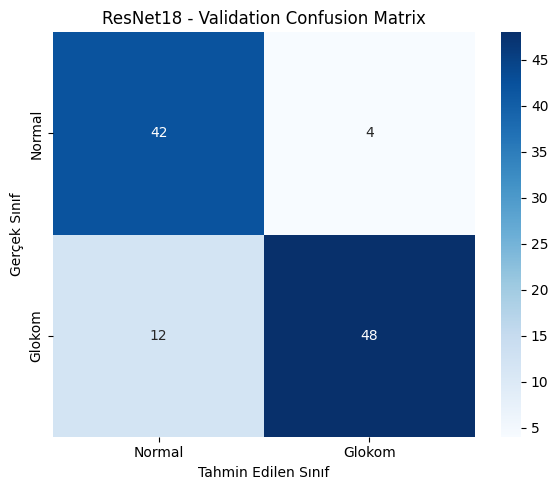

In [ ]:

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    balanced_accuracy_score
)
import matplotlib.pyplot as plt
import seaborn as sns
import torch

# En iyi ResNet18 ağırlıklarını yükle
resnet18.load_state_dict(
    torch.load(
        ROOT / "models" / "resnet18_best.pth",
        map_location=device,
        weights_only=True
    )
)

resnet18.eval()

resnet_gercek = []
resnet_tahmin = []

# Validation değerlendirmesi
with torch.no_grad():
    for goruntuler, etiketler in val_loader:

        goruntuler = goruntuler.to(device)

        cikti = resnet18(goruntuler)
        predicted = torch.argmax(cikti, dim=1)

        resnet_gercek.extend(etiketler.numpy())
        resnet_tahmin.extend(predicted.cpu().numpy())

# Performans ölçütleri
resnet_accuracy = accuracy_score(
    resnet_gercek, resnet_tahmin
)

resnet_macro_f1 = f1_score(
    resnet_gercek,
    resnet_tahmin,
    average="macro"
)

resnet_balanced_acc = balanced_accuracy_score(
    resnet_gercek, resnet_tahmin
)

print("ResNet18 Validation Accuracy:", round(resnet_accuracy, 4))
print("ResNet18 Validation Macro F1:", round(resnet_macro_f1, 4))
print("Balanced Accuracy:", round(resnet_balanced_acc, 4))

print("\nClassification Report:")
print(classification_report(
    resnet_gercek,
    resnet_tahmin,
    target_names=["Normal", "Glokom"],
    digits=4
))

# Confusion Matrix
resnet_cm = confusion_matrix(
    resnet_gercek,
    resnet_tahmin,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    resnet_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Glokom"],
    yticklabels=["Normal", "Glokom"]
)

plt.title("ResNet18 - Validation Confusion Matrix")
plt.xlabel("Tahmin Edilen Sınıf")
plt.ylabel("Gerçek Sınıf")
plt.tight_layout()
plt.show()


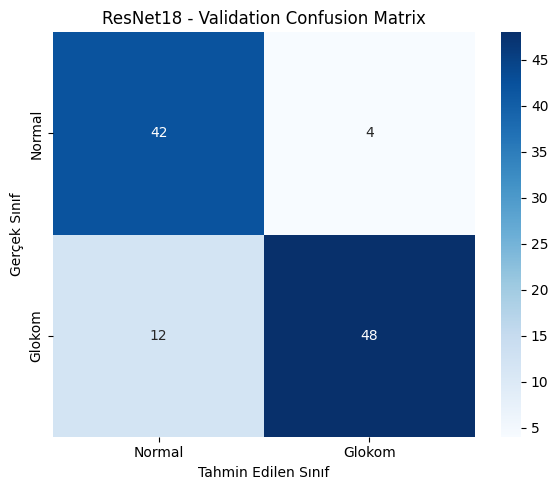

ResNet18 sonuçları kaydedildi!
                        model veri_kumesi  accuracy  macro_f1  \
0  ResNet18_FeatureExtraction  validation  0.849057  0.848571   

   balanced_accuracy  seed  best_epoch  
0           0.856522    42           8  


In [ ]:

import pandas as pd

# Sonuç tablosu
resnet_sonuclar = pd.DataFrame([{
    "model": "ResNet18_FeatureExtraction",
    "veri_kumesi": "validation",
    "accuracy": resnet_accuracy,
    "macro_f1": resnet_macro_f1,
    "balanced_accuracy": resnet_balanced_acc,
    "seed": 42,
    "best_epoch": best_epoch
}])

# Klasörleri kontrol et
(ROOT / "results").mkdir(parents=True, exist_ok=True)
(ROOT / "figures").mkdir(parents=True, exist_ok=True)

# Sonuçları kaydet
resnet_sonuclar.to_csv(
    ROOT / "results" / "resnet18_results.csv",
    index=False
)

# Eğitim geçmişini kaydet
resnet_history = pd.DataFrame({
    "epoch": range(1, len(resnet_train_losses) + 1),
    "train_loss": resnet_train_losses,
    "val_macro_f1": resnet_val_f1_scores
})

resnet_history.to_csv(
    ROOT / "results" / "resnet18_history.csv",
    index=False
)

# Hata matrisini kaydet
plt.figure(figsize=(6, 5))

sns.heatmap(
    resnet_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Glokom"],
    yticklabels=["Normal", "Glokom"]
)

plt.title("ResNet18 - Validation Confusion Matrix")
plt.xlabel("Tahmin Edilen Sınıf")
plt.ylabel("Gerçek Sınıf")

plt.tight_layout()
plt.savefig(
    ROOT / "figures" / "resnet18_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("ResNet18 sonuçları kaydedildi!")
print(resnet_sonuclar)


In [ ]:

import copy
import torch
import torch.nn as nn
import torch.optim as optim

# Önceki ResNet18 modelinin ayrı bir kopyasını oluştur
resnet_finetune = copy.deepcopy(resnet18)

# En iyi Feature Extraction ağırlıklarını yükle
resnet_finetune.load_state_dict(
    torch.load(
        ROOT / "models" / "resnet18_best.pth",
        map_location=device,
        weights_only=True
    )
)

# Önce bütün katmanları dondur
for param in resnet_finetune.parameters():
    param.requires_grad = False

# Son convolution bloğunu eğitime aç
for param in resnet_finetune.layer4.parameters():
    param.requires_grad = True

# Son sınıflandırma katmanını eğitime aç
for param in resnet_finetune.fc.parameters():
    param.requires_grad = True

resnet_finetune = resnet_finetune.to(device)

# Farklı katmanlara farklı öğrenme hızları
finetune_optimizer = optim.Adam([
    {
        "params": resnet_finetune.layer4.parameters(),
        "lr": 0.00001
    },
    {
        "params": resnet_finetune.fc.parameters(),
        "lr": 0.0001
    }
])

finetune_criterion = nn.CrossEntropyLoss()
finetune_epochs = 10

# Eğitilebilir parametreleri hesapla
trainable_params = sum(
    p.numel()
    for p in resnet_finetune.parameters()
    if p.requires_grad
)

print("Fine-Tuning modeli hazır!")
print("Eğitilebilir parametre:", trainable_params)
print("Epoch:", finetune_epochs)
print("Kullanılan cihaz:", device)


Fine-Tuning modeli hazır!
Eğitilebilir parametre: 8394754
Epoch: 10
Kullanılan cihaz: cuda


In [ ]:

from sklearn.metrics import f1_score
import torch

# Eğitim sonuçlarını sakla
finetune_train_losses = []
finetune_val_f1_scores = []

finetune_best_f1 = -1.0
finetune_best_epoch = 0

model_dir = ROOT / "models"
model_dir.mkdir(parents=True, exist_ok=True)

# Fine-Tuning eğitim döngüsü
for epoch in range(finetune_epochs):

    # Modeli eğitim moduna al
    resnet_finetune.train()

    # Dondurulmuş katmanların BatchNorm
    # istatistiklerini sabit tut
    for name, module in resnet_finetune.named_modules():
        if isinstance(module, torch.nn.BatchNorm2d):
            module.eval()

    toplam_loss = 0.0

    # TRAINING
    for goruntuler, etiketler in train_loader:

        goruntuler = goruntuler.to(device)
        etiketler = etiketler.to(device)

        finetune_optimizer.zero_grad()

        # Forward
        cikti = resnet_finetune(goruntuler)

        # Loss
        loss = finetune_criterion(cikti, etiketler)

        # Backward
        loss.backward()

        # Ağırlıkları güncelle
        finetune_optimizer.step()

        toplam_loss += loss.item() * goruntuler.size(0)

    train_loss = toplam_loss / len(train_dataset)

    # VALIDATION
    resnet_finetune.eval()

    gercek = []
    tahmin = []

    with torch.no_grad():
        for goruntuler, etiketler in val_loader:

            goruntuler = goruntuler.to(device)

            cikti = resnet_finetune(goruntuler)
            predicted = torch.argmax(cikti, dim=1)

            gercek.extend(etiketler.numpy())
            tahmin.extend(predicted.cpu().numpy())

    macro_f1 = f1_score(
        gercek,
        tahmin,
        average="macro",
        zero_division=0
    )

    finetune_train_losses.append(train_loss)
    finetune_val_f1_scores.append(macro_f1)

    # En iyi modeli kaydet
    if macro_f1 > finetune_best_f1:

        finetune_best_f1 = macro_f1
        finetune_best_epoch = epoch + 1

        torch.save(
            resnet_finetune.state_dict(),
            model_dir / "resnet18_finetuned_best.pth"
        )

    print(
        f"Epoch {epoch+1}/{finetune_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Validation Macro F1: {macro_f1:.4f}"
    )

print("\nResNet18 Fine-Tuning tamamlandı!")
print("En iyi epoch:", finetune_best_epoch)
print(
    f"En iyi Validation Macro F1: "
    f"{finetune_best_f1:.4f}"
)


Epoch 1/10 | Train Loss: 0.2780 | Validation Macro F1: 0.8579
Epoch 2/10 | Train Loss: 0.2112 | Validation Macro F1: 0.8672
Epoch 3/10 | Train Loss: 0.1451 | Validation Macro F1: 0.8760
Epoch 4/10 | Train Loss: 0.1218 | Validation Macro F1: 0.8946
Epoch 5/10 | Train Loss: 0.0922 | Validation Macro F1: 0.8946
Epoch 6/10 | Train Loss: 0.0879 | Validation Macro F1: 0.8853
Epoch 7/10 | Train Loss: 0.0835 | Validation Macro F1: 0.9040
Epoch 8/10 | Train Loss: 0.0369 | Validation Macro F1: 0.8579
Epoch 9/10 | Train Loss: 0.0489 | Validation Macro F1: 0.8946
Epoch 10/10 | Train Loss: 0.0337 | Validation Macro F1: 0.8579

ResNet18 Fine-Tuning tamamlandı!
En iyi epoch: 7
En iyi Validation Macro F1: 0.9040


Fine-Tuning Accuracy: 0.9057
Fine-Tuning Macro F1: 0.904
Balanced Accuracy: 0.904

Classification Report:
              precision    recall  f1-score   support

      Normal     0.8913    0.8913    0.8913        46
      Glokom     0.9167    0.9167    0.9167        60

    accuracy                         0.9057       106
   macro avg     0.9040    0.9040    0.9040       106
weighted avg     0.9057    0.9057    0.9057       106



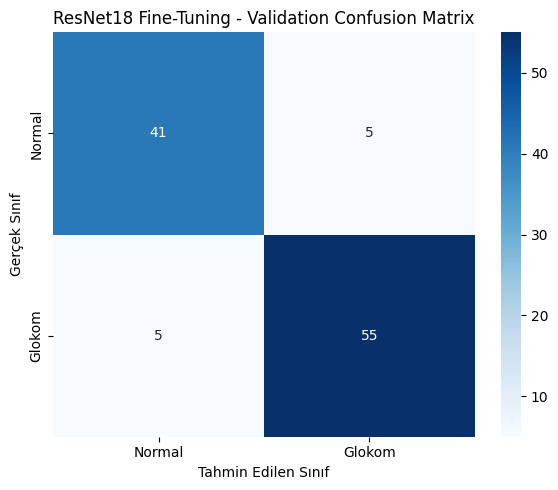

In [ ]:

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns
import torch

# En iyi Fine-Tuning modelini yükle
resnet_finetune.load_state_dict(
    torch.load(
        ROOT / "models" / "resnet18_finetuned_best.pth",
        map_location=device,
        weights_only=True
    )
)

resnet_finetune.eval()

finetune_gercek = []
finetune_tahmin = []

# Validation değerlendirmesi
with torch.no_grad():
    for goruntuler, etiketler in val_loader:

        goruntuler = goruntuler.to(device)

        cikti = resnet_finetune(goruntuler)
        predicted = torch.argmax(cikti, dim=1)

        finetune_gercek.extend(etiketler.numpy())
        finetune_tahmin.extend(predicted.cpu().numpy())

# Performans metrikleri
finetune_accuracy = accuracy_score(
    finetune_gercek, finetune_tahmin
)

finetune_macro_f1 = f1_score(
    finetune_gercek,
    finetune_tahmin,
    average="macro",
    zero_division=0
)

finetune_balanced_acc = balanced_accuracy_score(
    finetune_gercek, finetune_tahmin
)

print("Fine-Tuning Accuracy:", round(finetune_accuracy, 4))
print("Fine-Tuning Macro F1:", round(finetune_macro_f1, 4))
print("Balanced Accuracy:", round(finetune_balanced_acc, 4))

print("\nClassification Report:")
print(classification_report(
    finetune_gercek,
    finetune_tahmin,
    target_names=["Normal", "Glokom"],
    digits=4
))

# Confusion Matrix
finetune_cm = confusion_matrix(
    finetune_gercek,
    finetune_tahmin,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    finetune_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Glokom"],
    yticklabels=["Normal", "Glokom"]
)

plt.title("ResNet18 Fine-Tuning - Validation Confusion Matrix")
plt.xlabel("Tahmin Edilen Sınıf")
plt.ylabel("Gerçek Sınıf")

plt.tight_layout()
plt.show()


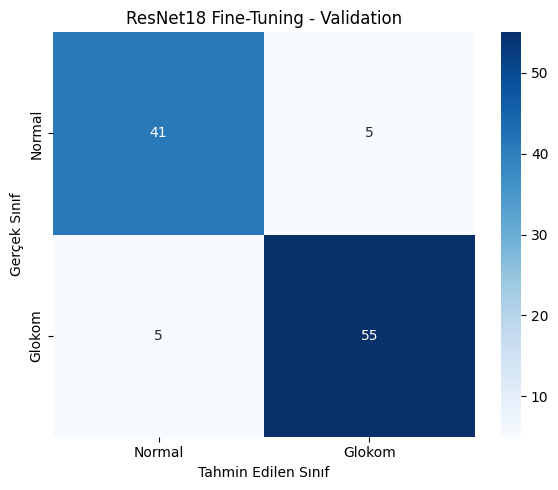

Fine-Tuning sonuçları kaydedildi!
                 model veri_kumesi  accuracy  macro_f1  balanced_accuracy  \
0  ResNet18_FineTuning  validation   0.90566  0.903986           0.903986   

   seed  best_epoch  
0    42           7  


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import balanced_accuracy_score

# Sonuç tablosu
finetune_sonuclar = pd.DataFrame([{
    "model": "ResNet18_FineTuning",
    "veri_kumesi": "validation",
    "accuracy": finetune_accuracy,
    "macro_f1": finetune_macro_f1,
    "balanced_accuracy": finetune_balanced_acc,
    "seed": 42,
    "best_epoch": finetune_best_epoch
}])

# Sonuçları kaydet
finetune_sonuclar.to_csv(
    ROOT / "results" / "resnet18_finetuned_results.csv",
    index=False
)

# Eğitim geçmişini kaydet
finetune_history = pd.DataFrame({
    "epoch": range(1, len(finetune_train_losses) + 1),
    "train_loss": finetune_train_losses,
    "val_macro_f1": finetune_val_f1_scores
})

finetune_history.to_csv(
    ROOT / "results" / "resnet18_finetuned_history.csv",
    index=False
)

# Confusion Matrix grafiği
plt.figure(figsize=(6, 5))

sns.heatmap(
    finetune_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Glokom"],
    yticklabels=["Normal", "Glokom"]
)

plt.title("ResNet18 Fine-Tuning - Validation")
plt.xlabel("Tahmin Edilen Sınıf")
plt.ylabel("Gerçek Sınıf")

plt.tight_layout()

plt.savefig(
    ROOT / "figures" / "resnet18_finetuned_cm.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Fine-Tuning sonuçları kaydedildi!")
print(finetune_sonuclar)


In [ ]:

import pandas as pd

# Beş modelin kayıtlı sonuçları
dosyalar = [
    "baseline_results.csv",
    "simple_cnn_results.csv",
    "deep_cnn_results.csv",
    "resnet18_results.csv",
    "resnet18_finetuned_results.csv"
]

# Sonuç dosyalarını oku
tablolar = []

for dosya in dosyalar:
    df = pd.read_csv(ROOT / "results" / dosya)
    tablolar.append(df)

# Tüm sonuçları birleştir
karsilastirma = pd.concat(
    tablolar,
    ignore_index=True
)

# Macro F1'e göre sırala
karsilastirma = karsilastirma.sort_values(
    by="macro_f1",
    ascending=False
).reset_index(drop=True)

# Karşılaştırma tablosunu kaydet
karsilastirma.to_csv(
    ROOT / "results" / "model_comparison.csv",
    index=False
)

# Tabloyu göster
print("ACRIMA - Model Karşılaştırması")
print(
    karsilastirma[
        ["model", "accuracy", "macro_f1",
         "balanced_accuracy"]
    ].round(4)
)

print("\nKarşılaştırma tablosu kaydedildi!")


ACRIMA - Model Karşılaştırması
                        model  accuracy  macro_f1  balanced_accuracy
0                     DeepCNN    0.9434    0.9429             0.9475
1         ResNet18_FineTuning    0.9057    0.9040             0.9040
2                   SimpleCNN    0.8585    0.8527             0.8471
3  ResNet18_FeatureExtraction    0.8491    0.8486             0.8565
4                     HOG_SVM    0.8113    0.8057             0.8029

Karşılaştırma tablosu kaydedildi!


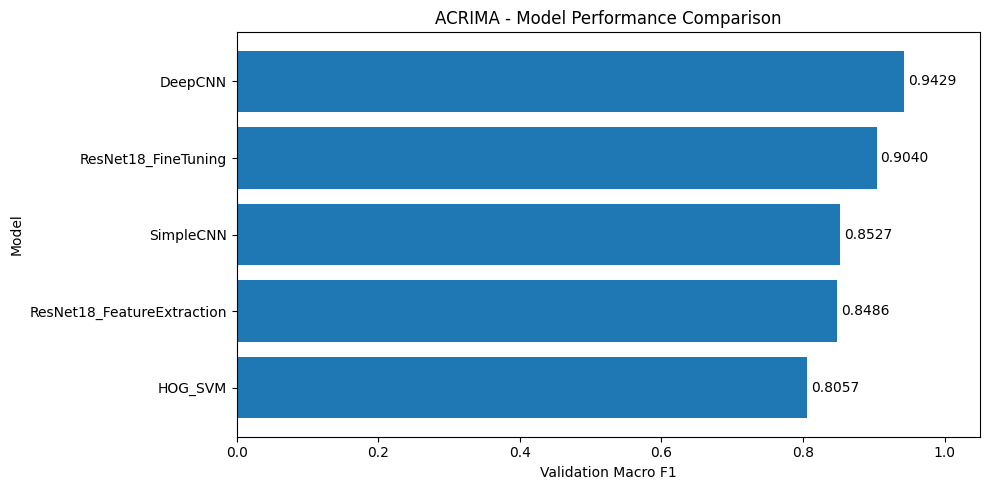

Model karşılaştırma grafiği kaydedildi!


In [ ]:

import matplotlib.pyplot as plt

# Modelleri Macro F1'e göre sırala
grafik_df = karsilastirma.sort_values(
    by="macro_f1",
    ascending=True
)

plt.figure(figsize=(10, 5))

# Yatay çubuk grafik
plt.barh(
    grafik_df["model"],
    grafik_df["macro_f1"]
)

# Değerleri çubukların yanına yaz
for i, deger in enumerate(grafik_df["macro_f1"]):
    plt.text(
        deger + 0.005,
        i,
        f"{deger:.4f}",
        va="center"
    )

plt.xlabel("Validation Macro F1")
plt.ylabel("Model")
plt.title("ACRIMA - Model Performance Comparison")
plt.xlim(0, 1.05)

plt.tight_layout()

# Grafiği Drive'a kaydet
plt.savefig(
    ROOT / "figures" / "model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Model karşılaştırma grafiği kaydedildi!")


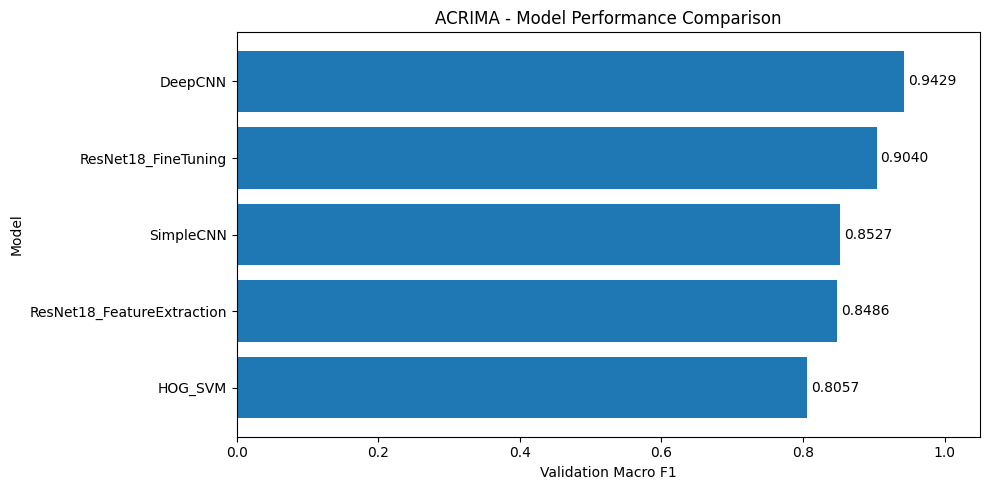

Model karşılaştırma grafiği kaydedildi!


In [ ]:

import matplotlib.pyplot as plt

# Modelleri Macro F1'e göre sırala
grafik_df = karsilastirma.sort_values(
    by="macro_f1",
    ascending=True
)

plt.figure(figsize=(10, 5))

# Yatay çubuk grafik
plt.barh(
    grafik_df["model"],
    grafik_df["macro_f1"]
)

# Değerleri çubukların yanına yaz
for i, deger in enumerate(grafik_df["macro_f1"]):
    plt.text(
        deger + 0.005,
        i,
        f"{deger:.4f}",
        va="center"
    )

plt.xlabel("Validation Macro F1")
plt.ylabel("Model")
plt.title("ACRIMA - Model Performance Comparison")
plt.xlim(0, 1.05)

plt.tight_layout()

# Grafiği Drive'a kaydet
plt.savefig(
    ROOT / "figures" / "model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Model karşılaştırma grafiği kaydedildi!")


In [ ]:

import pandas as pd
import hashlib

# Kaydedilmiş veri bölmelerini oku
train_df = pd.read_csv(ROOT / "data/splits/train.csv")
val_df = pd.read_csv(ROOT / "data/splits/val.csv")
test_df = pd.read_csv(ROOT / "data/splits/test.csv")

# Dosya adlarını karşılaştır
train_set = set(train_df["dosya_adi"])
val_set = set(val_df["dosya_adi"])
test_set = set(test_df["dosya_adi"])

print("Train-Val ortak:", len(train_set & val_set))
print("Train-Test ortak:", len(train_set & test_set))
print("Val-Test ortak:", len(val_set & test_set))

# Görüntülerin SHA256 hash değerlerini hesapla
def hash_hesapla(dosya_adi):
    path = image_dir / dosya_adi

    with open(path, "rb") as f:
        return hashlib.sha256(f.read()).hexdigest()

train_hash = set(map(hash_hesapla, train_set))
val_hash = set(map(hash_hesapla, val_set))
test_hash = set(map(hash_hesapla, test_set))

print("\nGörüntü içeriği kontrolü:")
print("Train-Val aynı içerik:", len(train_hash & val_hash))
print("Train-Test aynı içerik:", len(train_hash & test_hash))
print("Val-Test aynı içerik:", len(val_hash & test_hash))

# Genel kontrol
assert len(train_set | val_set | test_set) == 705
assert not (train_hash & val_hash)
assert not (train_hash & test_hash)
assert not (val_hash & test_hash)

print("\nDosya ve birebir içerik kontrolü başarılı!")


Train-Val ortak: 0
Train-Test ortak: 0
Val-Test ortak: 0

Görüntü içeriği kontrolü:
Train-Val aynı içerik: 0
Train-Test aynı içerik: 0
Val-Test aynı içerik: 0

Dosya ve birebir içerik kontrolü başarılı!


In [ ]:

import pandas as pd

# Veri bölmesi kontrol sonuçları
leakage_results = pd.DataFrame([
    {
        "kontrol": "Train-Val",
        "ortak_dosya": len(train_set & val_set),
        "ortak_hash": len(train_hash & val_hash)
    },
    {
        "kontrol": "Train-Test",
        "ortak_dosya": len(train_set & test_set),
        "ortak_hash": len(train_hash & test_hash)
    },
    {
        "kontrol": "Val-Test",
        "ortak_dosya": len(val_set & test_set),
        "ortak_hash": len(val_hash & test_hash)
    }
])

# Raporu kaydet
leakage_results.to_csv(
    ROOT / "results" / "data_leakage_check.csv",
    index=False
)

print("Data Leakage kontrol raporu kaydedildi!")
print(leakage_results)


Data Leakage kontrol raporu kaydedildi!
      kontrol  ortak_dosya  ortak_hash
0   Train-Val            0           0
1  Train-Test            0           0
2    Val-Test            0           0


In [ ]:

from PIL import Image
import numpy as np
from scipy.fft import dctn
import pandas as pd

# Görüntünün perceptual hash değerini hesapla
def phash_hesapla(dosya_adi):
    with Image.open(image_dir / dosya_adi) as img:
        img = img.convert("L").resize((32, 32))
        piksel = np.asarray(img, dtype=np.float32)

    # Discrete Cosine Transform
    dct = dctn(piksel, norm="ortho")

    # Düşük frekans bileşenlerini al
    blok = dct[:8, :8].copy()

    # DC bileşenini medyan hesabından çıkar
    medyan = np.median(blok.flatten()[1:])

    return blok > medyan


# İki hash arasındaki Hamming Distance
def hash_uzakligi(hash1, hash2):
    return int(np.count_nonzero(hash1 != hash2))


# Görüntülerin hash değerlerini hesapla
tum_dosyalar = sorted(
    train_set | val_set | test_set
)

hashler = {
    dosya: phash_hesapla(dosya)
    for dosya in tum_dosyalar
}

print("pHash hesaplanan görüntü:", len(hashler))

# Farklı bölmeler arasındaki benzer çiftleri bul
bolmeler = {
    "train": sorted(train_set),
    "validation": sorted(val_set),
    "test": sorted(test_set)
}

benzer_ciftler = []

bolme_ciftleri = [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test")
]

for bolme1, bolme2 in bolme_ciftleri:
    for dosya1 in bolmeler[bolme1]:
        for dosya2 in bolmeler[bolme2]:

            uzaklik = hash_uzakligi(
                hashler[dosya1],
                hashler[dosya2]
            )

            if uzaklik <= 10:
                benzer_ciftler.append({
                    "dosya1": dosya1,
                    "dosya2": dosya2,
                    "bolme1": bolme1,
                    "bolme2": bolme2,
                    "phash_uzakligi": uzaklik
                })

benzer_df = pd.DataFrame(
    benzer_ciftler,
    columns=[
        "dosya1", "dosya2",
        "bolme1", "bolme2",
        "phash_uzakligi"
    ]
)

benzer_df = benzer_df.sort_values(
    by="phash_uzakligi"
).reset_index(drop=True)

print("Şüpheli benzer çift sayısı:", len(benzer_df))
print("\nİlk 10 şüpheli çift:")
print(benzer_df.head(10))


pHash hesaplanan görüntü: 705
Şüpheli benzer çift sayısı: 21

İlk 10 şüpheli çift:
               dosya1              dosya2 bolme1      bolme2  phash_uzakligi
0  Im503_g_ACRIMA.jpg  Im705_g_ACRIMA.jpg  train        test               8
1    Im046_ACRIMA.jpg  Im371_g_ACRIMA.jpg  train  validation              10
2  Im313_g_ACRIMA.jpg  Im527_g_ACRIMA.jpg  train  validation              10
3    Im055_ACRIMA.jpg    Im275_ACRIMA.jpg  train  validation              10
4  Im505_g_ACRIMA.jpg  Im561_g_ACRIMA.jpg  train  validation              10
5  Im557_g_ACRIMA.jpg    Im016_ACRIMA.jpg  train  validation              10
6    Im082_ACRIMA.jpg    Im086_ACRIMA.jpg  train        test              10
7  Im348_g_ACRIMA.jpg    Im092_ACRIMA.jpg  train  validation              10
8    Im176_ACRIMA.jpg    Im086_ACRIMA.jpg  train        test              10
9    Im199_ACRIMA.jpg    Im048_ACRIMA.jpg  train        test              10


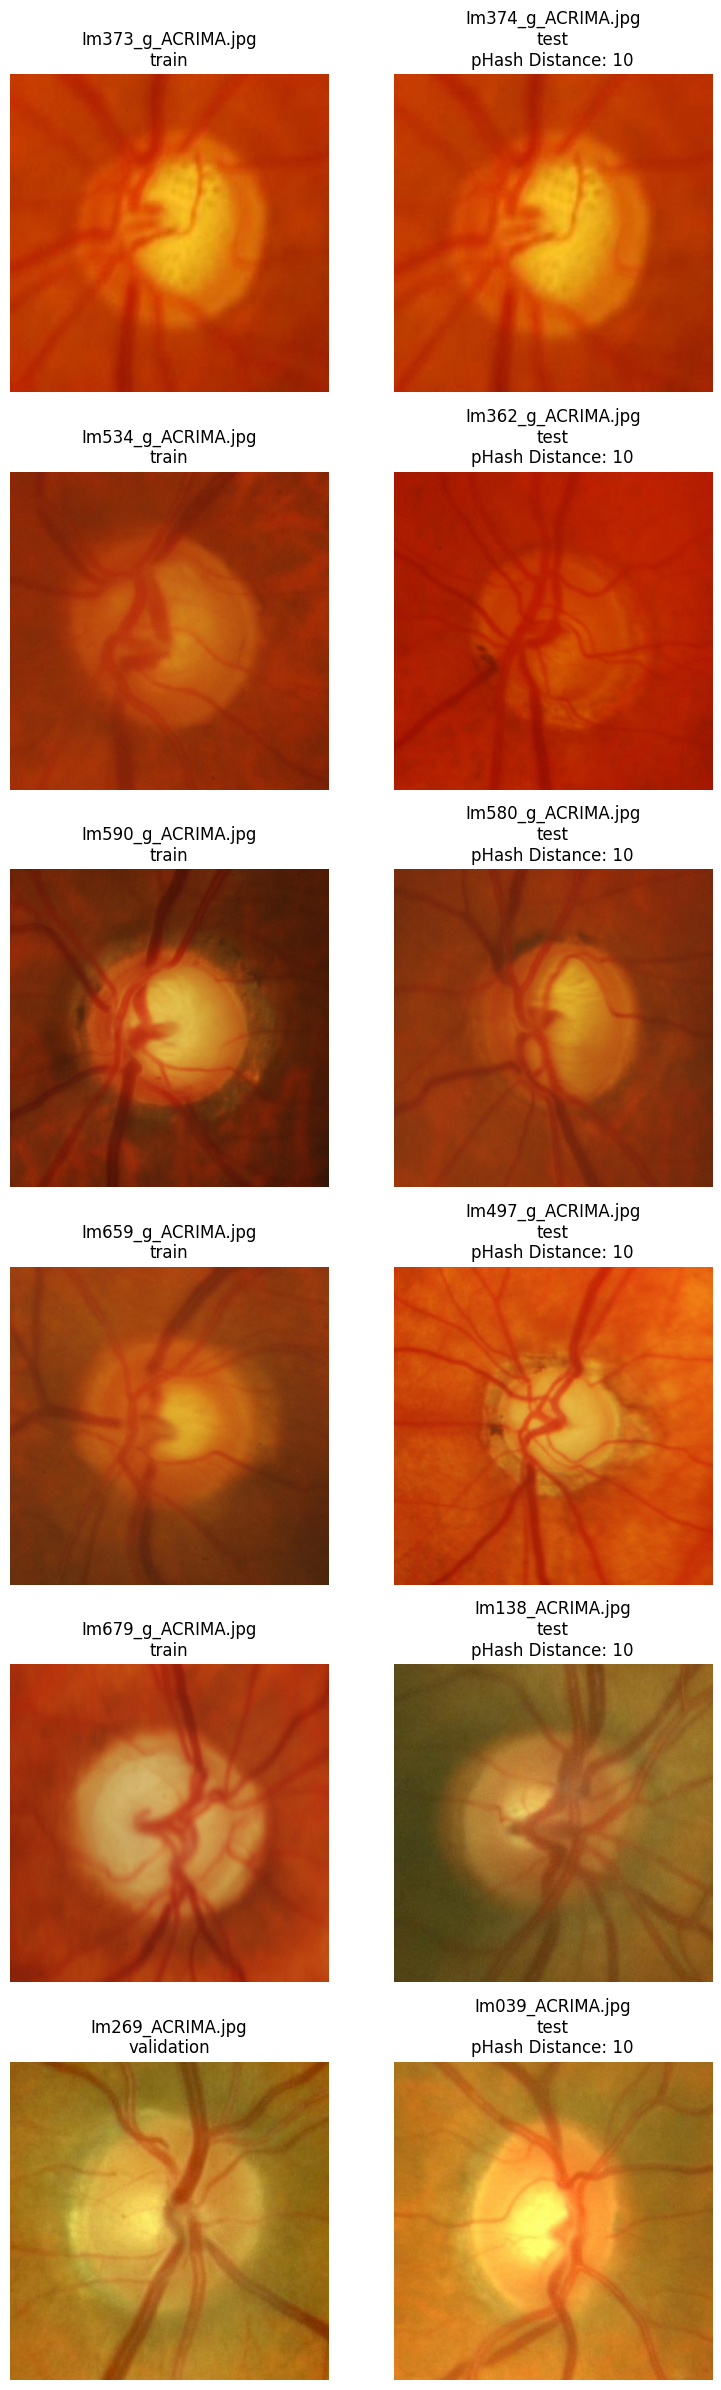

Şüpheli görüntü çiftleri görselleştirildi!


In [ ]:

import matplotlib.pyplot as plt
from PIL import Image

# En düşük pHash uzaklığına sahip ilk 5 çift
ilk_ciftler = benzer_df.iloc[15:21]

fig, axes = plt.subplots(
    len(ilk_ciftler), 2,
    figsize=(8, 4 * len(ilk_ciftler))
)

for i, (_, satir) in enumerate(ilk_ciftler.iterrows()):

    dosya1 = satir["dosya1"]
    dosya2 = satir["dosya2"]

    with Image.open(image_dir / dosya1) as img:
        image1 = img.convert("RGB").copy()

    with Image.open(image_dir / dosya2) as img:
        image2 = img.convert("RGB").copy()

    axes[i, 0].imshow(image1)
    axes[i, 0].set_title(
        f"{dosya1}\n{satir['bolme1']}"
    )
    axes[i, 0].axis("off")

    axes[i, 1].imshow(image2)
    axes[i, 1].set_title(
        f"{dosya2}\n{satir['bolme2']}\n"
        f"pHash Distance: {satir['phash_uzakligi']}"
    )
    axes[i, 1].axis("off")

plt.tight_layout()

plt.savefig(
    ROOT / "figures" / "suspicious_image_pairs.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Şüpheli görüntü çiftleri görselleştirildi!")


In [ ]:
import numpy as np
from PIL import Image
from skimage.metrics import structural_similarity as ssim

dosya1 = "Im373_g_ACRIMA.jpg"
dosya2 = "Im374_g_ACRIMA.jpg"

def goruntu_oku(ad):
    with Image.open(image_dir / ad) as img:
        return np.array(
            img.convert("L").resize((256, 256))
        )

img1 = goruntu_oku(dosya1)
img2 = goruntu_oku(dosya2)

skor = ssim(img1, img2, data_range=255)

print("SSIM:", round(skor, 4))

SSIM: 0.8832


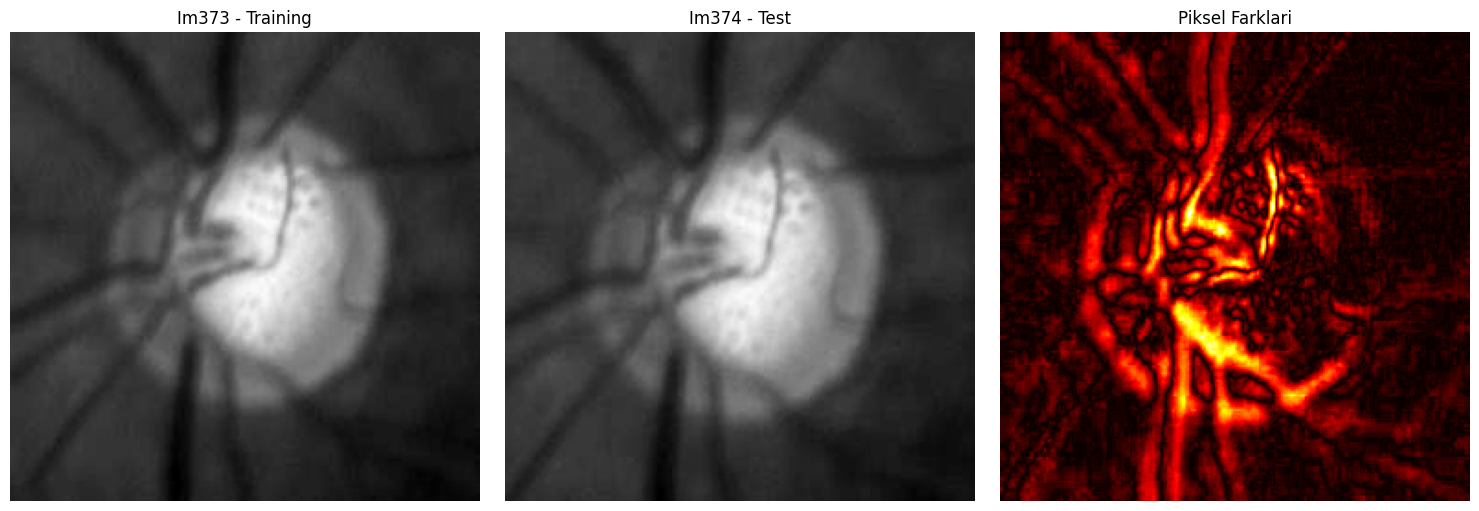

Ortalama mutlak piksel farkı: 4.52


In [ ]:

import matplotlib.pyplot as plt
import numpy as np

# İki görüntü arasındaki mutlak fark
fark = np.abs(
    img1.astype(np.float32) -
    img2.astype(np.float32)
)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(img1, cmap="gray")
axes[0].set_title("Im373 - Training")
axes[0].axis("off")

axes[1].imshow(img2, cmap="gray")
axes[1].set_title("Im374 - Test")
axes[1].axis("off")

axes[2].imshow(fark, cmap="hot")
axes[2].set_title("Piksel Farklari")
axes[2].axis("off")

plt.tight_layout()
plt.show()

print("Ortalama mutlak piksel farkı:", round(fark.mean(), 2))


In [ ]:

import pandas as pd

supheli_kayit = pd.DataFrame([{
    "dosya1": "Im373_g_ACRIMA.jpg",
    "dosya2": "Im374_g_ACRIMA.jpg",
    "bolme1": "train",
    "bolme2": "test",
    "ssim": 0.8832,
    "mean_absolute_pixel_difference": 4.52,
    "phash_distance": 10,
    "durum": "Yuksek tekrar suphesi - dogrulama gerekli"
}])

rapor_yolu = ROOT / "results" / "suspected_duplicates.csv"

supheli_kayit.to_csv(
    rapor_yolu,
    index=False
)

print("Şüpheli tekrar raporu kaydedildi!")
print(supheli_kayit)


Şüpheli tekrar raporu kaydedildi!
               dosya1              dosya2 bolme1 bolme2    ssim  \
0  Im373_g_ACRIMA.jpg  Im374_g_ACRIMA.jpg  train   test  0.8832   

   mean_absolute_pixel_difference  phash_distance  \
0                            4.52              10   

                                       durum  
0  Yuksek tekrar suphesi - dogrulama gerekli  


In [ ]:

from skimage.metrics import structural_similarity as ssim
from PIL import Image
import numpy as np
import pandas as pd

def goruntu_oku(ad):
    with Image.open(image_dir / ad) as img:
        return np.array(
            img.convert("L").resize((256, 256))
        )

sonuclar = []

for _, satir in benzer_df.iterrows():
    img1 = goruntu_oku(satir["dosya1"])
    img2 = goruntu_oku(satir["dosya2"])

    skor = ssim(img1, img2, data_range=255)

    sonuclar.append({
        "dosya1": satir["dosya1"],
        "dosya2": satir["dosya2"],
        "bolme1": satir["bolme1"],
        "bolme2": satir["bolme2"],
        "phash_distance": satir["phash_uzakligi"],
        "ssim": skor
    })

ssim_df = pd.DataFrame(sonuclar)

# En yüksek SSIM değerinden sırala
ssim_df = ssim_df.sort_values(
    by="ssim",
    ascending=False
).reset_index(drop=True)

# Sonuçları kaydet
ssim_df.to_csv(
    ROOT / "results" / "near_duplicate_ssim_results.csv",
    index=False
)

print("SSIM analizi tamamlandı!")
print(ssim_df.to_string(index=False))


SSIM analizi tamamlandı!
            dosya1             dosya2     bolme1     bolme2  phash_distance     ssim
Im373_g_ACRIMA.jpg Im374_g_ACRIMA.jpg      train       test              10 0.883160
Im313_g_ACRIMA.jpg Im527_g_ACRIMA.jpg      train validation              10 0.865543
Im534_g_ACRIMA.jpg Im362_g_ACRIMA.jpg      train       test              10 0.852054
Im505_g_ACRIMA.jpg Im561_g_ACRIMA.jpg      train validation              10 0.825776
Im590_g_ACRIMA.jpg Im580_g_ACRIMA.jpg      train       test              10 0.760169
Im503_g_ACRIMA.jpg Im705_g_ACRIMA.jpg      train       test               8 0.758783
Im313_g_ACRIMA.jpg Im523_g_ACRIMA.jpg      train       test              10 0.743724
  Im241_ACRIMA.jpg   Im250_ACRIMA.jpg      train       test              10 0.739847
  Im176_ACRIMA.jpg   Im086_ACRIMA.jpg      train       test              10 0.734177
Im679_g_ACRIMA.jpg   Im138_ACRIMA.jpg      train       test              10 0.727528
Im557_g_ACRIMA.jpg   Im016_ACRIMA.jpg   

In [ ]:

from google.colab import drive
from pathlib import Path
import pandas as pd
import zipfile

# Google Drive'a bağlan
drive.mount("/content/drive")

# Proje klasörü
ROOT = Path("/content/drive/MyDrive/ACRIMA_Glaucoma_Project")

# Önceki SSIM sonuçlarını yükle
ssim_df = pd.read_csv(
    ROOT / "results" / "near_duplicate_ssim_results.csv"
)

# Görüntüleri yeniden çıkar
image_dir = Path("/content/acrima_data/Database/Images")

if not image_dir.exists():
    with zipfile.ZipFile(ROOT / "Database.zip", "r") as z:
        z.extractall("/content/acrima_data")

print("SSIM sonuçları yüklendi:", len(ssim_df))
print("Görüntü klasörü mevcut:", image_dir.exists())


Mounted at /content/drive
SSIM sonuçları yüklendi: 21
Görüntü klasörü mevcut: True


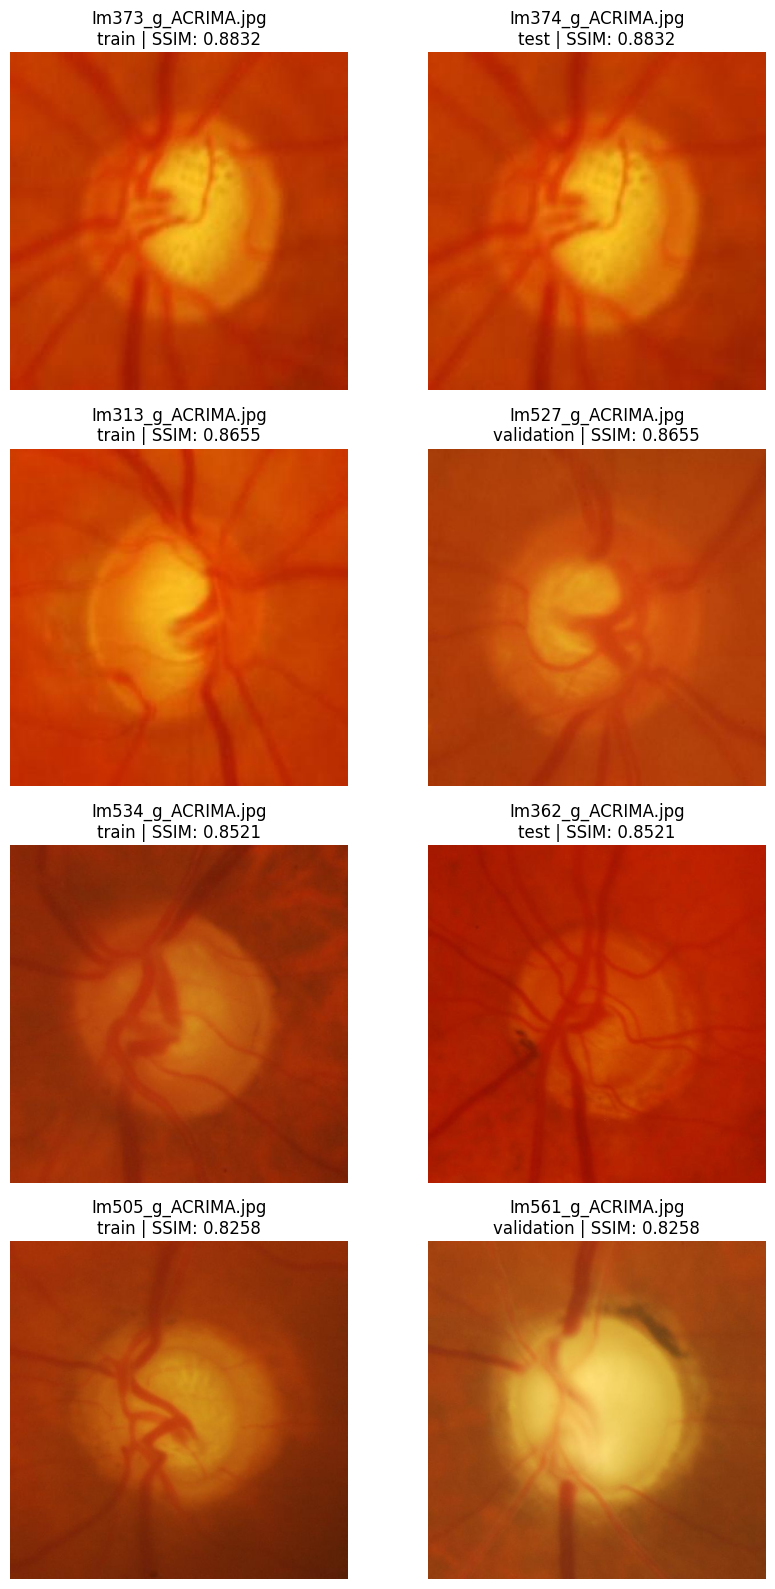

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

# SSIM değeri en yüksek dört çift
supheli_dortlu = ssim_df.head(4)

fig, axes = plt.subplots(4, 2, figsize=(9, 16))

for i, (_, satir) in enumerate(supheli_dortlu.iterrows()):
    for j, kolon in enumerate(["dosya1", "dosya2"]):
        dosya = satir[kolon]

        with Image.open(image_dir / dosya) as img:
            axes[i, j].imshow(img.convert("RGB"))

        axes[i, j].set_title(
            f"{dosya}\n"
            f"{satir['bolme1'] if j == 0 else satir['bolme2']}"
            f" | SSIM: {satir['ssim']:.4f}"
        )
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()



Görüntü çifti: Im373_g_ACRIMA.jpg - Im374_g_ACRIMA.jpg
Birinci görüntü özellik sayısı: 23
İkinci görüntü özellik sayısı: 22
İyi eşleşme sayısı: 21


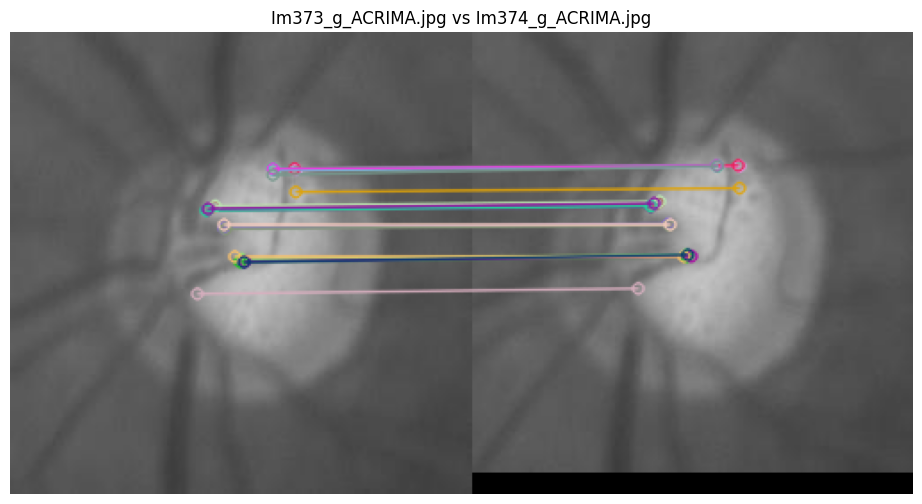

Yeterli özellik bulunamadı: Im313_g_ACRIMA.jpg Im527_g_ACRIMA.jpg


In [ ]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# İncelenecek iki kritik çift
ciftler = [
    ("Im373_g_ACRIMA.jpg", "Im374_g_ACRIMA.jpg"),
    ("Im313_g_ACRIMA.jpg", "Im527_g_ACRIMA.jpg")
]

orb = cv2.ORB_create(nfeatures=2000)

for dosya1, dosya2 in ciftler:

    img1 = cv2.imread(
        str(image_dir / dosya1),
        cv2.IMREAD_GRAYSCALE
    )

    img2 = cv2.imread(
        str(image_dir / dosya2),
        cv2.IMREAD_GRAYSCALE
    )

    if img1 is None or img2 is None:
        print("Görüntü okunamadı:", dosya1, dosya2)
        continue

    # Özellik noktalarını ve tanımlayıcıları bul
    kp1, des1 = orb.detectAndCompute(img1, None)
    kp2, des2 = orb.detectAndCompute(img2, None)

    if des1 is None or des2 is None:
        print("Yeterli özellik bulunamadı:", dosya1, dosya2)
        continue

    # Özellikleri karşılaştır
    matcher = cv2.BFMatcher(cv2.NORM_HAMMING)

    eslesmeler = matcher.knnMatch(
        des1, des2, k=2
    )

    # Lowe ratio testi
    iyi_eslesmeler = []

    for eslesme in eslesmeler:
        if len(eslesme) == 2:
            m, n = eslesme

            if m.distance < 0.75 * n.distance:
                iyi_eslesmeler.append(m)

    print("\nGörüntü çifti:", dosya1, "-", dosya2)
    print("Birinci görüntü özellik sayısı:", len(kp1))
    print("İkinci görüntü özellik sayısı:", len(kp2))
    print("İyi eşleşme sayısı:", len(iyi_eslesmeler))

    # En iyi eşleşmeleri görselleştir
    iyi_eslesmeler = sorted(
        iyi_eslesmeler,
        key=lambda x: x.distance
    )

    sonuc = cv2.drawMatches(
        img1, kp1,
        img2, kp2,
        iyi_eslesmeler[:40],
        None,
        flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
    )

    plt.figure(figsize=(14, 6))
    plt.imshow(sonuc, cmap="gray")
    plt.title(f"{dosya1} vs {dosya2}")
    plt.axis("off")
    plt.show()


İyi eşleşme sayısı: 21
RANSAC Inlier sayısı: 19
Inlier oranı: %90.48


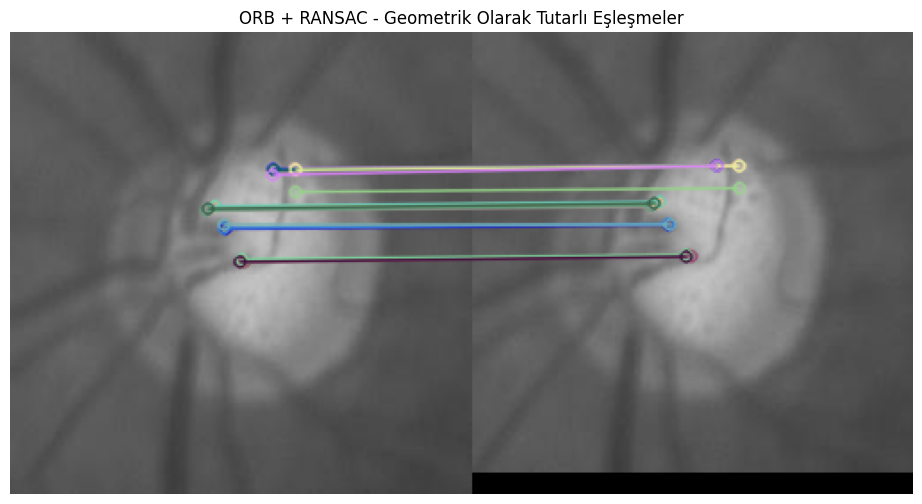

In [ ]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Öncelikle en şüpheli çiftimizi inceleyelim
dosya1 = "Im373_g_ACRIMA.jpg"
dosya2 = "Im374_g_ACRIMA.jpg"

img1 = cv2.imread(str(image_dir / dosya1), 0)
img2 = cv2.imread(str(image_dir / dosya2), 0)

assert img1 is not None and img2 is not None, "Görüntü okunamadı!"

# ORB özellik noktaları
orb = cv2.ORB_create(nfeatures=2000)

kp1, des1 = orb.detectAndCompute(img1, None)
kp2, des2 = orb.detectAndCompute(img2, None)

# Descriptor eşleştirme
matcher = cv2.BFMatcher(cv2.NORM_HAMMING)

matches = matcher.knnMatch(des1, des2, k=2)

iyi_eslesmeler = [
    m for m, n in matches
    if m.distance < 0.75 * n.distance
]

print("İyi eşleşme sayısı:", len(iyi_eslesmeler))

# Eşleşen noktaların koordinatlarını al
pts1 = np.float32([
    kp1[m.queryIdx].pt for m in iyi_eslesmeler
]).reshape(-1, 1, 2)

pts2 = np.float32([
    kp2[m.trainIdx].pt for m in iyi_eslesmeler
]).reshape(-1, 1, 2)

# RANSAC ile geometrik doğrulama
H, mask = cv2.findHomography(
    pts1,
    pts2,
    cv2.RANSAC,
    3.0
)

if H is None or mask is None:
    print("Geometrik dönüşüm hesaplanamadı.")
else:
    inlier_sayisi = int(mask.sum())
    inlier_orani = inlier_sayisi / len(iyi_eslesmeler)

    print("RANSAC Inlier sayısı:", inlier_sayisi)
    print(f"Inlier oranı: %{inlier_orani * 100:.2f}")

    # Yalnızca geometrik olarak tutarlı eşleşmeler
    sonuc = cv2.drawMatches(
        img1, kp1,
        img2, kp2,
        iyi_eslesmeler,
        None,
        matchesMask=mask.ravel().tolist(),
        flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
    )

    plt.figure(figsize=(14, 6))
    plt.imshow(sonuc, cmap="gray")
    plt.title("ORB + RANSAC - Geometrik Olarak Tutarlı Eşleşmeler")
    plt.axis("off")
    plt.show()


In [ ]:

import pandas as pd

ransac_raporu = pd.DataFrame([{
    "dosya1": "Im373_g_ACRIMA.jpg",
    "dosya2": "Im374_g_ACRIMA.jpg",
    "bolme1": "train",
    "bolme2": "test",
    "ssim": 0.883160,
    "orb_good_matches": 21,
    "ransac_inliers": 19,
    "ransac_inlier_ratio": 19 / 21,
    "durum": "Cok yuksek tekrar suphesi"
}])

kayit_yolu = ROOT / "results" / "ransac_duplicate_check.csv"

ransac_raporu.to_csv(
    kayit_yolu,
    index=False
)

print("RANSAC raporu kaydedildi!")
print(ransac_raporu)


RANSAC raporu kaydedildi!
               dosya1              dosya2 bolme1 bolme2     ssim  \
0  Im373_g_ACRIMA.jpg  Im374_g_ACRIMA.jpg  train   test  0.88316   

   orb_good_matches  ransac_inliers  ransac_inlier_ratio  \
0                21              19             0.904762   

                       durum  
0  Cok yuksek tekrar suphesi  


Görüntü 1 özellik sayısı: 2131
Görüntü 2 özellik sayısı: 2632
İyi eşleşme sayısı: 27
RANSAC Inlier sayısı: 5
Inlier oranı: %18.52


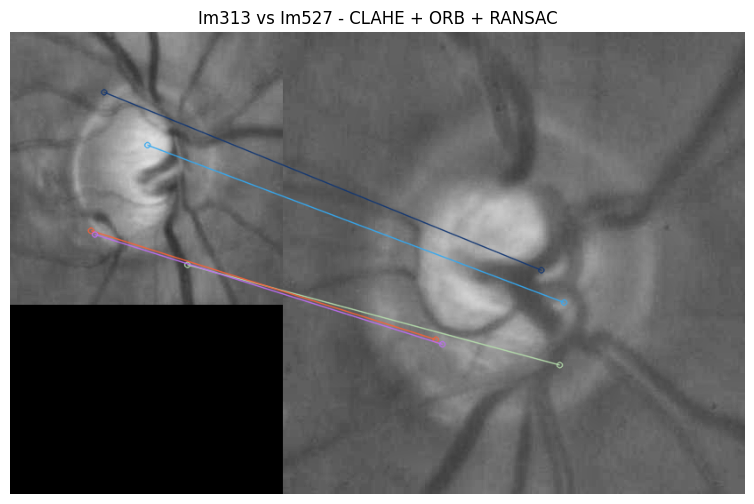

In [ ]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

dosya1 = "Im313_g_ACRIMA.jpg"
dosya2 = "Im527_g_ACRIMA.jpg"

img1 = cv2.imread(str(image_dir / dosya1), 0)
img2 = cv2.imread(str(image_dir / dosya2), 0)

assert img1 is not None and img2 is not None, "Görüntüler okunamadı!"

# CLAHE ile yerel kontrastı artır
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

img1_clahe = clahe.apply(img1)
img2_clahe = clahe.apply(img2)

# ORB özellikleri
orb = cv2.ORB_create(
    nfeatures=3000,
    fastThreshold=5
)

kp1, des1 = orb.detectAndCompute(img1_clahe, None)
kp2, des2 = orb.detectAndCompute(img2_clahe, None)

print("Görüntü 1 özellik sayısı:", len(kp1))
print("Görüntü 2 özellik sayısı:", len(kp2))

iyi_eslesmeler = []

if des1 is not None and des2 is not None:
    matcher = cv2.BFMatcher(cv2.NORM_HAMMING)

    matches = matcher.knnMatch(des1, des2, k=2)

    for eslesme in matches:
        if len(eslesme) == 2:
            m, n = eslesme
            if m.distance < 0.75 * n.distance:
                iyi_eslesmeler.append(m)

print("İyi eşleşme sayısı:", len(iyi_eslesmeler))

if len(iyi_eslesmeler) >= 4:

    pts1 = np.float32([
        kp1[m.queryIdx].pt for m in iyi_eslesmeler
    ]).reshape(-1, 1, 2)

    pts2 = np.float32([
        kp2[m.trainIdx].pt for m in iyi_eslesmeler
    ]).reshape(-1, 1, 2)

    H, mask = cv2.findHomography(
        pts1, pts2,
        cv2.RANSAC, 3.0
    )

    if H is not None and mask is not None:
        inliers = int(mask.sum())
        oran = inliers / len(iyi_eslesmeler)

        print("RANSAC Inlier sayısı:", inliers)
        print(f"Inlier oranı: %{oran*100:.2f}")

        sonuc = cv2.drawMatches(
            img1_clahe, kp1,
            img2_clahe, kp2,
            iyi_eslesmeler,
            None,
            matchesMask=mask.ravel().tolist(),
            flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
        )

        plt.figure(figsize=(14, 6))
        plt.imshow(sonuc, cmap="gray")
        plt.title("Im313 vs Im527 - CLAHE + ORB + RANSAC")
        plt.axis("off")
        plt.show()
    else:
        print("Geometrik dönüşüm hesaplanamadı.")
else:
    print("RANSAC için yeterli eşleşme bulunamadı.")


In [ ]:

import cv2
import numpy as np
import pandas as pd

# Daha önce incelenen iki çift
incelenenler = {
    frozenset(["Im373_g_ACRIMA.jpg", "Im374_g_ACRIMA.jpg"]),
    frozenset(["Im313_g_ACRIMA.jpg", "Im527_g_ACRIMA.jpg"])
}

clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

orb = cv2.ORB_create(
    nfeatures=3000,
    fastThreshold=5
)

matcher = cv2.BFMatcher(cv2.NORM_HAMMING)

sonuclar = []

for _, satir in ssim_df.iterrows():

    dosya1 = satir["dosya1"]
    dosya2 = satir["dosya2"]

    if frozenset([dosya1, dosya2]) in incelenenler:
        continue

    img1 = cv2.imread(str(image_dir / dosya1), 0)
    img2 = cv2.imread(str(image_dir / dosya2), 0)

    if img1 is None or img2 is None:
        print("Okunamayan dosya:", dosya1, dosya2)
        continue

    img1 = clahe.apply(img1)
    img2 = clahe.apply(img2)

    kp1, des1 = orb.detectAndCompute(img1, None)
    kp2, des2 = orb.detectAndCompute(img2, None)

    iyi = []

    if des1 is not None and des2 is not None:
        eslesmeler = matcher.knnMatch(des1, des2, k=2)

        for eslesme in eslesmeler:
            if len(eslesme) == 2:
                m, n = eslesme
                if m.distance < 0.75 * n.distance:
                    iyi.append(m)

    inlier = 0
    oran = np.nan

    if len(iyi) >= 4:
        pts1 = np.float32([
            kp1[m.queryIdx].pt for m in iyi
        ]).reshape(-1, 1, 2)

        pts2 = np.float32([
            kp2[m.trainIdx].pt for m in iyi
        ]).reshape(-1, 1, 2)

        try:
            H, mask = cv2.findHomography(
                pts1, pts2,
                cv2.RANSAC, 3.0
            )

            if H is not None and mask is not None:
                inlier = int(mask.sum())
                oran = inlier / len(iyi)
        except cv2.error:
            pass

    sonuclar.append({
        "dosya1": dosya1,
        "dosya2": dosya2,
        "bolme1": satir["bolme1"],
        "bolme2": satir["bolme2"],
        "ssim": satir["ssim"],
        "iyi_eslesme": len(iyi),
        "ransac_inlier": inlier,
        "inlier_orani": oran
    })

ransac_df = pd.DataFrame(sonuclar)

ransac_df = ransac_df.sort_values(
    ["ransac_inlier", "inlier_orani"],
    ascending=False
)

# Sonuçları Drive'a kaydet
rapor = ROOT / "results" / "remaining_ransac_results.csv"
rapor.parent.mkdir(parents=True, exist_ok=True)

ransac_df.to_csv(rapor, index=False)

print("Kontrol edilen çift:", len(ransac_df))
print(ransac_df.to_string(index=False))
print("Rapor kaydedildi!")


Kontrol edilen çift: 19
            dosya1             dosya2     bolme1     bolme2     ssim  iyi_eslesme  ransac_inlier  inlier_orani
Im505_g_ACRIMA.jpg Im561_g_ACRIMA.jpg      train validation 0.825776           47              8      0.170213
Im503_g_ACRIMA.jpg Im705_g_ACRIMA.jpg      train       test 0.758783           49              8      0.163265
Im348_g_ACRIMA.jpg   Im092_ACRIMA.jpg      train validation 0.637808           54              8      0.148148
  Im199_ACRIMA.jpg   Im048_ACRIMA.jpg      train       test 0.665053           34              7      0.205882
  Im046_ACRIMA.jpg Im371_g_ACRIMA.jpg      train validation 0.694401           35              7      0.200000
Im534_g_ACRIMA.jpg Im362_g_ACRIMA.jpg      train       test 0.852054           42              7      0.166667
  Im269_ACRIMA.jpg   Im039_ACRIMA.jpg validation       test 0.655233           44              7      0.159091
Im679_g_ACRIMA.jpg   Im138_ACRIMA.jpg      train       test 0.727528           54       

In [ ]:

from PIL import Image
from skimage.metrics import structural_similarity as ssim
import numpy as np

dosya1 = "Im373_g_ACRIMA.jpg"
dosya2 = "Im374_g_ACRIMA.jpg"

with Image.open(image_dir / dosya1) as im:
    a = np.array(im.convert("RGB"))

with Image.open(image_dir / dosya2) as im:
    b = np.array(im.convert("RGB"))

print("Görüntü 1 boyutu:", a.shape)
print("Görüntü 2 boyutu:", b.shape)

if a.shape == b.shape:
    fark = np.abs(a.astype(np.float32) - b.astype(np.float32))

    print("Ortalama piksel farkı:", round(float(fark.mean()), 4))
    print("Maksimum piksel farkı:", float(fark.max()))
    print("Tamamen aynı piksel oranı (%):",
          round(float(np.mean(np.all(a == b, axis=2)) * 100), 2))

    gri_a = np.array(Image.fromarray(a).convert("L"))
    gri_b = np.array(Image.fromarray(b).convert("L"))

    print("Orijinal boyutta SSIM:",
          round(float(ssim(gri_a, gri_b, data_range=255)), 4))
else:
    print("Boyutlar farklı; doğrudan piksel karşılaştırması yapılmadı.")


Görüntü 1 boyutu: (259, 259, 3)
Görüntü 2 boyutu: (247, 247, 3)
Boyutlar farklı; doğrudan piksel karşılaştırması yapılmadı.


In [ ]:

import cv2
import numpy as np
from skimage.metrics import structural_similarity as ssim

# Görüntüleri orijinal boyutlarında yeniden oku
a = cv2.imread(str(image_dir / "Im373_g_ACRIMA.jpg"))
b = cv2.imread(str(image_dir / "Im374_g_ACRIMA.jpg"))

assert a is not None and b is not None

# İkinci görüntüyü birinciyle aynı boyuta getir
b_esit = cv2.resize(
    b,
    (a.shape[1], a.shape[0]),
    interpolation=cv2.INTER_LINEAR
)

# Grayscale görüntüler
gri_a = cv2.cvtColor(a, cv2.COLOR_BGR2GRAY)
gri_b = cv2.cvtColor(b_esit, cv2.COLOR_BGR2GRAY)

# Benzerlik ölçümleri
skor = ssim(gri_a, gri_b, data_range=255)

ortalama_fark = np.mean(
    np.abs(
        gri_a.astype(np.float32) -
        gri_b.astype(np.float32)
    )
)

print("Eşitlenmiş boyut:", gri_a.shape)
print("SSIM:", round(float(skor), 4))
print("Ortalama mutlak piksel farkı:",
      round(float(ortalama_fark), 4))


Eşitlenmiş boyut: (259, 259)
SSIM: 0.886
Ortalama mutlak piksel farkı: 4.4809


In [ ]:

from pathlib import Path
import pandas as pd
import shutil

split_dir = ROOT / "data" / "splits"
backup_dir = ROOT / "data" / "splits_backup_before_dedup"

backup_dir.mkdir(parents=True, exist_ok=True)

# Mevcut bölmeleri yedekle
for ad in ["train.csv", "val.csv", "test.csv"]:
    kaynak = split_dir / ad
    hedef = backup_dir / ad

    if kaynak.exists():
        if not hedef.exists():
            shutil.copy2(kaynak, hedef)
        print("Yedeklendi:", ad)
    else:
        print("Dosya bulunamadı:", ad)

print("\nVeri bölmelerinin yedeği hazır!")


Yedeklendi: train.csv
Yedeklendi: val.csv
Yedeklendi: test.csv

Veri bölmelerinin yedeği hazır!


In [ ]:

import pandas as pd
import random

# Yedeklediğimiz orijinal bölmeleri oku
train_yeni = pd.read_csv(backup_dir / "train.csv")
val_yeni = pd.read_csv(backup_dir / "val.csv")
test_yeni = pd.read_csv(backup_dir / "test.csv")

dosya_train = "Im373_g_ACRIMA.jpg"
dosya_test = "Im374_g_ACRIMA.jpg"

# Beklenen konumları kontrol et
assert dosya_train in train_yeni["dosya_adi"].values
assert dosya_test in test_yeni["dosya_adi"].values

# Diğer şüpheli çiftlerdeki dosyaları seçimden çıkar
supheli_dosyalar = set(ssim_df["dosya1"]) | set(ssim_df["dosya2"])

# Değiştirilecek glokom görüntüsü adayları
adaylar = sorted(
    train_yeni.loc[
        (train_yeni["sinif"] == "Glokom") &
        (~train_yeni["dosya_adi"].isin(supheli_dosyalar)),
        "dosya_adi"
    ].tolist()
)

assert len(adaylar) > 0, "Uygun değişim adayı bulunamadı."

# Sabit tohumla bir aday seç
rng = random.Random(42)
degisecek_dosya = rng.choice(adaylar)

# Im374'ü eğitim kümesine al
test_yeni = test_yeni[
    test_yeni["dosya_adi"] != dosya_test
].copy()

train_yeni = pd.concat([
    train_yeni,
    pd.DataFrame([{
        "dosya_adi": dosya_test,
        "sinif": "Glokom"
    }])
], ignore_index=True)

# Seçilen eğitim görüntüsünü test kümesine taşı
train_yeni = train_yeni[
    train_yeni["dosya_adi"] != degisecek_dosya
].copy()

test_yeni = pd.concat([
    test_yeni,
    pd.DataFrame([{
        "dosya_adi": degisecek_dosya,
        "sinif": "Glokom"
    }])
], ignore_index=True)

# Yeni veri bölmelerini ayrı klasöre kaydet
yeni_dir = ROOT / "data" / "splits_v2"
yeni_dir.mkdir(parents=True, exist_ok=True)

train_yeni.to_csv(yeni_dir / "train.csv", index=False)
val_yeni.to_csv(yeni_dir / "val.csv", index=False)
test_yeni.to_csv(yeni_dir / "test.csv", index=False)

# Son kontroller
train_set_yeni = set(train_yeni["dosya_adi"])
val_set_yeni = set(val_yeni["dosya_adi"])
test_set_yeni = set(test_yeni["dosya_adi"])

assert len(train_yeni) == 493
assert len(val_yeni) == 106
assert len(test_yeni) == 106

assert not (train_set_yeni & val_set_yeni)
assert not (train_set_yeni & test_set_yeni)
assert not (val_set_yeni & test_set_yeni)

assert len(train_set_yeni | val_set_yeni | test_set_yeni) == 705

assert dosya_train in train_set_yeni
assert dosya_test in train_set_yeni

print("Yeni veri bölmeleri kaydedildi!")
print("Değiştirilen görüntü:", degisecek_dosya)

print("\nTraining:", len(train_yeni))
print("Validation:", len(val_yeni))
print("Test:", len(test_yeni))

print("\nSınıf dağılımları:")
print("Training:\n", train_yeni["sinif"].value_counts())
print("Validation:\n", val_yeni["sinif"].value_counts())
print("Test:\n", test_yeni["sinif"].value_counts())

print("\nIm373 ve Im374 aynı kümede:",
      dosya_train in train_set_yeni and dosya_test in train_set_yeni)


Yeni veri bölmeleri kaydedildi!
Değiştirilen görüntü: Im395_g_ACRIMA.jpg

Training: 493
Validation: 106
Test: 106

Sınıf dağılımları:
Training:
 sinif
Glokom    277
Normal    216
Name: count, dtype: int64
Validation:
 sinif
Glokom    60
Normal    46
Name: count, dtype: int64
Test:
 sinif
Glokom    59
Normal    47
Name: count, dtype: int64

Im373 ve Im374 aynı kümede: True


In [ ]:

import pandas as pd

# Yeni bölmelerdeki dosyaların konumları
konum = {}

for ad, df in [
    ("train", train_yeni),
    ("validation", val_yeni),
    ("test", test_yeni)
]:
    for dosya in df["dosya_adi"]:
        konum[dosya] = ad

# Önceden bulunan 21 şüpheli çift
kontrol = ssim_df.copy()

kontrol["yeni_bolme1"] = kontrol["dosya1"].map(konum)
kontrol["yeni_bolme2"] = kontrol["dosya2"].map(konum)

kontrol["farkli_bolme"] = (
    kontrol["yeni_bolme1"] != kontrol["yeni_bolme2"]
)

# Tanımlı bütün dosyaların bulunmasını doğrula
assert kontrol[
    ["yeni_bolme1", "yeni_bolme2"]
].notna().all().all()

print("Toplam şüpheli çift:", len(kontrol))

print(
    "Farklı bölmelerde kalan şüpheli çift:",
    kontrol["farkli_bolme"].sum()
)

print("\nFarklı bölmelerde kalan çiftler:")

print(
    kontrol.loc[
        kontrol["farkli_bolme"],
        ["dosya1", "dosya2", "ssim",
         "yeni_bolme1", "yeni_bolme2"]
    ].to_string(index=False)
)

# Raporu kaydet
kontrol.to_csv(
    ROOT / "results" / "splits_v2_leakage_check.csv",
    index=False
)

print("\nKontrol raporu kaydedildi.")


Toplam şüpheli çift: 21
Farklı bölmelerde kalan şüpheli çift: 20

Farklı bölmelerde kalan çiftler:
            dosya1             dosya2     ssim yeni_bolme1 yeni_bolme2
Im313_g_ACRIMA.jpg Im527_g_ACRIMA.jpg 0.865543       train  validation
Im534_g_ACRIMA.jpg Im362_g_ACRIMA.jpg 0.852054       train        test
Im505_g_ACRIMA.jpg Im561_g_ACRIMA.jpg 0.825776       train  validation
Im590_g_ACRIMA.jpg Im580_g_ACRIMA.jpg 0.760169       train        test
Im503_g_ACRIMA.jpg Im705_g_ACRIMA.jpg 0.758783       train        test
Im313_g_ACRIMA.jpg Im523_g_ACRIMA.jpg 0.743724       train        test
  Im241_ACRIMA.jpg   Im250_ACRIMA.jpg 0.739847       train        test
  Im176_ACRIMA.jpg   Im086_ACRIMA.jpg 0.734177       train        test
Im679_g_ACRIMA.jpg   Im138_ACRIMA.jpg 0.727528       train        test
Im557_g_ACRIMA.jpg   Im016_ACRIMA.jpg 0.715752       train  validation
  Im082_ACRIMA.jpg   Im086_ACRIMA.jpg 0.705420       train        test
  Im046_ACRIMA.jpg Im371_g_ACRIMA.jpg 0.694401   

In [ ]:

from collections import defaultdict

# Tüm görüntüler
tum_dosyalar = (
    pd.concat([
        train_yeni,
        val_yeni,
        test_yeni
    ])["dosya_adi"].tolist()
)

parent = {dosya: dosya for dosya in tum_dosyalar}

def find(x):
    if parent[x] != x:
        parent[x] = find(parent[x])
    return parent[x]

def union(a, b):
    ra = find(a)
    rb = find(b)
    if ra != rb:
        parent[rb] = ra

# pHash ile şüpheli bulunan çiftleri aynı gruba bağla
for _, satir in ssim_df.iterrows():
    union(satir["dosya1"], satir["dosya2"])

gruplar = defaultdict(list)

for dosya in tum_dosyalar:
    gruplar[find(dosya)].append(dosya)

coklu_gruplar = [
    sorted(dosyalar)
    for dosyalar in gruplar.values()
    if len(dosyalar) > 1
]

print("Toplam görüntü:", len(tum_dosyalar))
print("Toplam grup:", len(gruplar))
print("Birden fazla görüntü içeren grup:", len(coklu_gruplar))

print("\nŞüpheli görüntü grupları:")

for i, grup in enumerate(coklu_gruplar, 1):
    print(f"\nGrup {i} ({len(grup)} görüntü):")
    for dosya in grup:
        print(" ", dosya)


Toplam görüntü: 705
Toplam grup: 684
Birden fazla görüntü içeren grup: 18

Şüpheli görüntü grupları:

Grup 1 (2 görüntü):
  Im180_ACRIMA.jpg
  Im299_ACRIMA.jpg

Grup 2 (2 görüntü):
  Im046_ACRIMA.jpg
  Im371_g_ACRIMA.jpg

Grup 3 (2 görüntü):
  Im580_g_ACRIMA.jpg
  Im590_g_ACRIMA.jpg

Grup 4 (2 görüntü):
  Im497_g_ACRIMA.jpg
  Im659_g_ACRIMA.jpg

Grup 5 (4 görüntü):
  Im082_ACRIMA.jpg
  Im086_ACRIMA.jpg
  Im176_ACRIMA.jpg
  Im305_ACRIMA.jpg

Grup 6 (2 görüntü):
  Im503_g_ACRIMA.jpg
  Im705_g_ACRIMA.jpg

Grup 7 (2 görüntü):
  Im055_ACRIMA.jpg
  Im275_ACRIMA.jpg

Grup 8 (2 görüntü):
  Im241_ACRIMA.jpg
  Im250_ACRIMA.jpg

Grup 9 (2 görüntü):
  Im016_ACRIMA.jpg
  Im557_g_ACRIMA.jpg

Grup 10 (2 görüntü):
  Im092_ACRIMA.jpg
  Im348_g_ACRIMA.jpg

Grup 11 (2 görüntü):
  Im505_g_ACRIMA.jpg
  Im561_g_ACRIMA.jpg

Grup 12 (2 görüntü):
  Im138_ACRIMA.jpg
  Im679_g_ACRIMA.jpg

Grup 13 (2 görüntü):
  Im047_ACRIMA.jpg
  Im293_ACRIMA.jpg

Grup 14 (2 görüntü):
  Im362_g_ACRIMA.jpg
  Im534_g_ACRIMA.jpg

G

In [ ]:
# Birden fazla sınıf içeren grupları bul
karisik_gruplar = sinif_sayilari[
    sinif_sayilari > 1
].index

print("Farklı sınıf içeren grup sayısı:", len(karisik_gruplar))

for grup in karisik_gruplar:
    print("\n--- ŞÜPHELİ GRUP ---")

    print(
        veri.loc[
            veri["grup"] == grup,
            ["dosya_adi", "sinif"]
        ].to_string(index=False)
    )


Farklı sınıf içeren grup sayısı: 4

--- ŞÜPHELİ GRUP ---
         dosya_adi  sinif
  Im046_ACRIMA.jpg Normal
Im371_g_ACRIMA.jpg Glokom

--- ŞÜPHELİ GRUP ---
         dosya_adi  sinif
Im348_g_ACRIMA.jpg Glokom
  Im092_ACRIMA.jpg Normal

--- ŞÜPHELİ GRUP ---
         dosya_adi  sinif
Im557_g_ACRIMA.jpg Glokom
  Im016_ACRIMA.jpg Normal

--- ŞÜPHELİ GRUP ---
         dosya_adi  sinif
Im679_g_ACRIMA.jpg Glokom
  Im138_ACRIMA.jpg Normal


In [ ]:

# Her görüntüyü başlangıçta ayrı grup yap
parent = {
    dosya: dosya
    for dosya in veri["dosya_adi"]
}

def find(x):
    if parent[x] != x:
        parent[x] = find(parent[x])
    return parent[x]

def union(a, b):
    ra = find(a)
    rb = find(b)

    if ra != rb:
        parent[rb] = ra

# Güçlü geometrik tekrar şüphesi olan çift
union(
    "Im373_g_ACRIMA.jpg",
    "Im374_g_ACRIMA.jpg"
)

# Grupları yeniden oluştur
veri["grup"] = veri["dosya_adi"].apply(find)

print("Toplam görüntü:", len(veri))
print("Toplam grup:", veri["grup"].nunique())

# Sınıf tutarlılığı
sinif_sayilari = veri.groupby("grup")["sinif"].nunique()

print(
    "Farklı sınıf içeren grup:",
    (sinif_sayilari > 1).sum()
)

# Kritik çiftin aynı grupta olduğunu doğrula
g1 = veri.loc[
    veri["dosya_adi"] == "Im373_g_ACRIMA.jpg",
    "grup"
].iloc[0]

g2 = veri.loc[
    veri["dosya_adi"] == "Im374_g_ACRIMA.jpg",
    "grup"
].iloc[0]

assert g1 == g2

print("Im373 ve Im374 aynı grupta:", g1 == g2)


Toplam görüntü: 705
Toplam grup: 704
Farklı sınıf içeren grup: 0
Im373 ve Im374 aynı grupta: True


In [ ]:

import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

# Daha önce hazırladığımız 704 grubu kullan
veri = veri.copy()

# Hedef görüntü sayıları
hedef = {
    "train": 493,
    "val": 106,
    "test": 106
}

en_iyi = None
en_iyi_puan = float("inf")

# Farklı aday bölmeleri dene
for seed in range(42, 62):

    sgkf1 = StratifiedGroupKFold(
        n_splits=7,
        shuffle=True,
        random_state=seed
    )

    for trainval_idx, test_idx in sgkf1.split(
        veri, veri["sinif"], veri["grup"]
    ):

        trainval = veri.iloc[trainval_idx]
        test = veri.iloc[test_idx]

        sgkf2 = StratifiedGroupKFold(
            n_splits=6,
            shuffle=True,
            random_state=seed
        )

        for train_idx, val_idx in sgkf2.split(
            trainval,
            trainval["sinif"],
            trainval["grup"]
        ):

            train = trainval.iloc[train_idx]
            val = trainval.iloc[val_idx]

            puan = (
                abs(len(train) - hedef["train"]) +
                abs(len(val) - hedef["val"]) +
                abs(len(test) - hedef["test"])
            )

            if puan < en_iyi_puan:
                en_iyi_puan = puan
                en_iyi = (
                    train.copy(),
                    val.copy(),
                    test.copy(),
                    seed
                )

train_v3, val_v3, test_v3, secilen_seed = en_iyi

# Grup ve görüntü kesişim kontrolleri
for a, b in [
    (train_v3, val_v3),
    (train_v3, test_v3),
    (val_v3, test_v3)
]:
    assert set(a["grup"]).isdisjoint(set(b["grup"]))
    assert set(a["dosya_adi"]).isdisjoint(set(b["dosya_adi"]))

assert len(train_v3) + len(val_v3) + len(test_v3) == 705

# Yeni CSV dosyalarını kaydet
v3_dir = ROOT / "data" / "splits_v3"
v3_dir.mkdir(parents=True, exist_ok=True)

for ad, df in [
    ("train", train_v3),
    ("val", val_v3),
    ("test", test_v3)
]:
    df[["dosya_adi", "sinif"]].to_csv(
        v3_dir / f"{ad}.csv",
        index=False
    )

    print(f"\n{ad.upper()}: {len(df)} görüntü")
    print(df["sinif"].value_counts().to_string())

print("\nSeçilen rastgele tohum:", secilen_seed)
print("Hedefe toplam sapma:", en_iyi_puan)
print("Yeni ayrım kaydedildi:", v3_dir)



TRAIN: 502 görüntü
sinif
Glokom    282
Normal    220

VAL: 102 görüntü
sinif
Glokom    57
Normal    45

TEST: 101 görüntü
sinif
Glokom    57
Normal    44

Seçilen rastgele tohum: 42
Hedefe toplam sapma: 18
Yeni ayrım kaydedildi: /content/drive/MyDrive/ACRIMA_Glaucoma_Project/data/splits_v3


In [ ]:

# Yeni bölmelerdeki dosya ve grup kontrolleri

bolmeler = {
    "train": train_v3,
    "validation": val_v3,
    "test": test_v3
}

for ad, df in bolmeler.items():
    print(f"{ad}: {len(df)} görüntü")
    print("Tekrarlanan dosya adı:", df["dosya_adi"].duplicated().sum())

for ad1, ad2 in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test")
]:
    ortak_dosya = (
        set(bolmeler[ad1]["dosya_adi"])
        & set(bolmeler[ad2]["dosya_adi"])
    )

    ortak_grup = (
        set(bolmeler[ad1]["grup"])
        & set(bolmeler[ad2]["grup"])
    )

    print(
        f"{ad1} - {ad2}: "
        f"{len(ortak_dosya)} ortak dosya, "
        f"{len(ortak_grup)} ortak grup"
    )

# Güçlü tekrar şüphesi olan çiftin konumu
for dosya in [
    "Im373_g_ACRIMA.jpg",
    "Im374_g_ACRIMA.jpg"
]:
    for ad, df in bolmeler.items():
        if dosya in df["dosya_adi"].values:
            print(dosya, "->", ad)


train: 502 görüntü
Tekrarlanan dosya adı: 0
validation: 102 görüntü
Tekrarlanan dosya adı: 0
test: 101 görüntü
Tekrarlanan dosya adı: 0
train - validation: 0 ortak dosya, 0 ortak grup
train - test: 0 ortak dosya, 0 ortak grup
validation - test: 0 ortak dosya, 0 ortak grup
Im373_g_ACRIMA.jpg -> validation
Im374_g_ACRIMA.jpg -> validation


In [ ]:

from google.colab import drive
from pathlib import Path
import pandas as pd

drive.mount("/content/drive")

ROOT = Path(
    "/content/drive/MyDrive/ACRIMA_Glaucoma_Project"
)

# Yeni veri ayrımımız
SPLIT_DIR = ROOT / "data" / "splits_v3"

train_df = pd.read_csv(SPLIT_DIR / "train.csv")
val_df = pd.read_csv(SPLIT_DIR / "val.csv")
test_df = pd.read_csv(SPLIT_DIR / "test.csv")

print("TRAIN:", len(train_df))
print("VALIDATION:", len(val_df))
print("TEST:", len(test_df))

print("\nSınıf dağılımları:")
for ad, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{ad}")
    print(df["sinif"].value_counts())

# Bölmeler arasında aynı dosya bulunmamalı
train_files = set(train_df["dosya_adi"])
val_files = set(val_df["dosya_adi"])
test_files = set(test_df["dosya_adi"])

assert train_files.isdisjoint(val_files)
assert train_files.isdisjoint(test_files)
assert val_files.isdisjoint(test_files)

print("\nYeni veri ayrımı başarıyla yüklendi!")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TRAIN: 502
VALIDATION: 102
TEST: 101

Sınıf dağılımları:

Train
sinif
Glokom    282
Normal    220
Name: count, dtype: int64

Validation
sinif
Glokom    57
Normal    45
Name: count, dtype: int64

Test
sinif
Glokom    57
Normal    44
Name: count, dtype: int64

Yeni veri ayrımı başarıyla yüklendi!


In [ ]:

import torch
import zipfile
from pathlib import Path

# Görüntü klasörü
image_dir = Path("/content/acrima_data/Database/Images")

# Colab oturumu sıfırlandıysa görüntüleri yeniden çıkar
if not image_dir.exists():
    print("Görüntüler ZIP dosyasından çıkarılıyor...")

    with zipfile.ZipFile(ROOT / "Database.zip", "r") as z:
        z.extractall("/content/acrima_data")

# GPU kontrolü
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Kullanılan cihaz:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Bütün eğitim ve doğrulama görüntüleri mevcut mu?
eksikler = [
    ad for ad in pd.concat([
        train_df, val_df
    ])["dosya_adi"]
    if not (image_dir / ad).is_file()
]

print("Eksik görüntü sayısı:", len(eksikler))
print("Görüntü klasörü:", image_dir)

assert len(eksikler) == 0, "Eksik görüntüler var!"
print("Eğitim için görüntüler hazır!")


Kullanılan cihaz: cpu
Eksik görüntü sayısı: 0
Görüntü klasörü: /content/acrima_data/Database/Images
Eğitim için görüntüler hazır!
